# Capstone project: Black Box Optimisation for Imperial College Professional Certificate in Machine Learning and Artificial Intelligence.


### 1. Python Libraries and Subroutines

In [268]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.stats import qmc
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

# Import our visualization functions
from plotting_utils import (
    plot_gp_1d, plot_acquisition_1d, plot_bo_iteration_1d,
    plot_2d_function, plot_2d_bo_state, plot_convergence,
    plot_parallel_coordinates
)
from pathlib import Path
import sys


# Set random seed for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-darkgrid')

### 2. Load all initial input about the functions into a single structure called data

There are the initial function inputs and outputs in .npy files and there is information about the functions copied from the course as coded values. The existing tries are sorted in order of ascending output for ease of inspection

In [244]:


# ---------------------------------------------------------
# 1. Load the .npy data for each function into a dictionary
# ---------------------------------------------------------
base_path = Path(r'Initial_data_points_starter\initial_data')

data = {}
for i in range(1, 9):
    folder = base_path / f'function_{i}'
    data[i] = {
        'inputs': np.load(folder / 'initial_inputs.npy'),
        'outputs': np.load(folder / 'initial_outputs.npy'),
    }
    # sort in ascending order so the max is close to the end 
    order = np.argsort(data[i]['outputs'])[::1]    # indices that sort outputs ascending -1 for descending+

    sorted_outputs = data[i]['outputs'][order]       # reorder the 1D array
    sorted_inputs  = data[i]['inputs'][order]        # reorder the 2D array's ROWS the same way
    data[i]['outputs'] = sorted_outputs 
    data[i]['inputs'] = sorted_inputs

# ---------------------------------------------------------
# 2. Hardcoded descriptive metadata for each function
# ---------------------------------------------------------
function_info = {
    1: {
        'input_dim': '2D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.',
        'description': (
            "Detect likely contamination sources in a two-dimensional area, such as a radiation "
            "field, where only proximity yields a non-zero reading. The system uses Bayesian "
            "optimisation to tune detection parameters and reliably identify both strong and weak sources."
        ),
    },
    2: {
        'input_dim': '2D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima.',
        'description': (
            "Imagine a black box, or a mystery ML model, that takes two numbers as input and returns "
            "a log-likelihood score. Your goal is to maximise that score, but each output is noisy, "
            "and depending on where you start, you might get stuck in a local optimum.\n\n"
            "To tackle this, you use Bayesian optimisation, which selects the next inputs based on "
            "what it has learned so far. It balances exploration with exploitation, making it well "
            "suited to noisy outputs and complex functions with many local peaks."
        ),
    },
    3: {
        'input_dim': '3D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Minimise drug side effects (framed as maximisation) across 3 compound-dose inputs.',
        'description': (
            "You're working on a drug discovery project, testing combinations of three compounds to "
            "create a new medicine.\n\n"
            "Each experiment is stored in initial_inputs.npy as a 3D array, where each row lists the "
            "amounts of the three compounds used. After each experiment, you record the number of "
            "adverse reactions, stored in initial_outputs.npy as a 1D array.\n\n"
            "Your goal is to minimise side effects; in this competition, it is framed as maximisation "
            "by optimising a transformed output (e.g. the negative of side effects)."
        ),
    },
    4: {
        'input_dim': '4D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Tune 4 hyperparameters of a warehouse-placement approximation model against an expensive baseline.',
        'description': (
            "Address the challenge of optimally placing products across warehouses for a business "
            "with high online sales, where accurate calculations are costly and only feasible "
            "biweekly. To speed up decision-making, an ML model approximates these results within "
            "hours. The model has four hyperparameters to tune, and its output reflects the "
            "difference from the expensive baseline. Because the system is dynamic and full of "
            "local optima, it requires careful tuning and robust validation to find reliable, "
            "near-optimal solutions."
        ),
    },
    5: {
        'input_dim': '4D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Maximise yield of a unimodal 4-input chemical process.',
        'description': (
            "You're tasked with optimising a four-variable black-box function that represents the "
            "yield of a chemical process in a factory. The function is typically unimodal, with a "
            "single peak where yield is maximised.\n\n"
            "Your goal is to find the optimal combination of chemical inputs that delivers the "
            "highest possible yield, using systematic exploration and optimisation methods."
        ),
    },
    6: {
        'input_dim': '5D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Optimise a 5-ingredient cake recipe, maximising a negative expert-judged score toward zero.',
        'description': (
            "You're optimising a cake recipe using a black-box function with five ingredient inputs, "
            "for example flour, sugar, eggs, butter and milk. Each recipe is evaluated with a "
            "combined score based on flavour, consistency, calories, waste and cost, where each "
            "factor contributes negative points as judged by an expert taster. This means the total "
            "score is negative by design.\n\n"
            "To frame this as a maximisation problem, your goal is to bring that score as close to "
            "zero as possible or, equivalently, to maximise the negative of the total sum."
        ),
    },
    7: {
        'input_dim': '6D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Maximise ML model performance by tuning 6 hyperparameters.',
        'description': (
            "You're tasked with optimising an ML model by tuning six hyperparameters, for example "
            "learning rate, regularisation strength or number of hidden layers. The function you're "
            "maximising is the model's performance score (such as accuracy or F1), but since the "
            "relationship between inputs and output isn't known, it's treated as a black-box function.\n\n"
            "Because this is a commonly used model, you might benefit from researching best practices "
            "or literature to guide your initial search space. Your goal is to find the combination "
            "of hyperparameters that yields the highest possible performance."
        ),
    },
    8: {
        'input_dim': '8D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Maximise an 8-hyperparameter validation accuracy score; strong local maxima are a practical target.',
        'description': (
            "You're optimising an eight-dimensional black-box function, where each of the eight "
            "input parameters affects the output, but the internal mechanics are unknown.\n\n"
            "Your objective is to find the parameter combination that maximises the function's "
            "output, such as performance, efficiency or validation accuracy. Because the function is "
            "high-dimensional and likely complex, global optimisation is hard, so identifying strong "
            "local maxima is often a practical strategy.\n\n"
            "For example, imagine you're tuning an ML model with eight hyperparameters: learning "
            "rate, batch size, number of layers, dropout rate, regularisation strength, activation "
            "function (numerically encoded), optimiser type (encoded) and initial weight range. Each "
            "input set returns a single validation accuracy score between 0 and 1. Your goal is to "
            "maximise this score."
        ),
    },
}

# ---------------------------------------------------------
# 3. Add the real element count, read straight from the data
#    (rather than hardcoded, so it's always accurate)
# ---------------------------------------------------------
for i in range(1, 9):
    function_info[i]['original_reading_count'] = data[i]['outputs'].shape[0]
    function_info[i]['reading_count'] = function_info[i]['original_reading_count'] 

# ---------------------------------------------------------
# 4. Merge info into the data dict for single-point access
# ---------------------------------------------------------
for i in range(1, 9):
    data[i]['info'] = function_info[i]
print (data[1])



{'inputs': array([[0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.84035342, 0.26473161],
       [0.08250725, 0.40348751],
       [0.31940389, 0.76295937],
       [0.88388983, 0.58225397],
       [0.57432921, 0.8798981 ],
       [0.68341817, 0.86105746],
       [0.73102363, 0.73299988]]), 'outputs': array([-3.60606264e-003, -2.15924904e-054, -2.08909327e-091,
        3.34177101e-124,  3.60677119e-081,  1.32267704e-079,
        6.22985647e-048,  1.03307824e-046,  2.53500115e-040,
        7.71087511e-016]), 'info': {'input_dim': '2D array', 'output_dim': '1D array', 'goal': 'Maximise', 'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.', 'description': 'Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and 

### 3 Load the Additional Inputs and Outputs from each week's submission

The Capstone Portal returns an email containing input.txt and output.txt. Their contents are converted into code and appended to the initial array.

The week numbers shown are the Module week of the class 12 to 24. To convert to Capstone weeks substract 11.

In [ ]:
# load additional readings week 12
inputs_week12 = [
    [0.529898, 0.147279],
    [0.708951, 0.],
    [1., 1., 0.828175],
    [0.425474, 0.395517, 0.36094, 0.411679],
    [0.257143, 0.49982, 1., 0.99297],
    [0.289894, 0., 0.147955, 1., 0.],
    [0., 0.338137, 0.355396, 0.132998, 0.372845, 0.773692],
    [0.141895, 0.095432, 0.159456, 0., 1., 0.379385, 0.137654, 0.33106],
]
outputs_week12 = np.array(
[4.053428008350997e-63,
 0.5552587474771571,
 -0.07941258446450565,
 0.6125296791453043,
 1711.945439547402,
 -1.353607855778981,
 1.677647239313782,
 9.918854085501]    
)
for i, row in enumerate(inputs_week12):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['original_reading_count'] + 1
for i, col in enumerate(outputs_week12):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])



In [ ]:
# load additional readings week 13
inputs_week13 = [
[0.02725 , 0.086909],
[0.961968, 0.      ],
[0., 0., 0.],
[0.434583, 0.429955, 0.200617, 0.449818],
[1., 0., 1., 1.],
[0.141044, 1.      , 0.      , 1.      , 0.049934],
[0.      , 0.164509, 0.031516, 0.      , 0.355541, 1.      ],
[0.122837, 0.132208, 0.111196, 0.282165, 1.      , 0.557382,
       0.250889, 0.974698]

]
outputs_week13 = np.array(
[-1.1964394027512214e-186,
 0.024151137433858324,
 -0.17239781799687137,
 -3.1185913551321742,
 4440.5225,
 -1.7437453725953456,
 0.3634687180335354,
 9.9376000954386]
)
for i, row in enumerate(inputs_week13):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week13):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])



In [ ]:
# load additional readings week 14
inputs_week14 = [

[0.839255, 0.104077],
[0.689358, 1.      ],
[0.55, 0.65, 0.15],
[0.3806, 0.4001, 0.4317, 0.4443],
[0.95, 0.02, 1.  , 1.  ],
[0.735, 0.14 , 0.745, 0.7  , 0.05 ],
[0.  , 0.4 , 0.3 , 0.2 , 0.39, 0.76],
[0.13 , 0.11 , 0.135, 0.15 , 1.   , 0.465, 0.19 , 0.5  ]
]
outputs_week14 = np.array(
[-2.748441588472043e-192,
 0.6445010131383366,
 -0.09261282572565534,
 0.10596447065193049,
 3819.753553371859,
 -0.7481068297892876,
 1.6532943330108063,
 9.9741]
)
for i, row in enumerate(inputs_week14):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week14):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 15
inputs_week15 = (
[
[0.731024, 0.743   ],
[0.     , 0.82931],
[0.78964 , 1.      , 0.439476],
[0., 0., 1., 1.],
[1.      , 0.56135 , 0.428393, 0.98753 ],
[0.578043, 0.299842, 1.      , 1.      , 0.      ],
[0.      , 0.425438, 0.333622, 0.248521, 0.405577, 0.806397],
[0.228797, 0.351247, 0.037923, 0.320776, 0.054109, 0.088993,
       0.154376, 0.881937]
]
)
outputs_week15 = np.array(
[6.0934518405813155e-18,
 -0.10536269821157246,
 -0.04510980150700221,
 -40.34848959671252,
 1819.6725727760238,
 -0.961669160895994,
 1.4899938109121635,
 9.4125079546716]
)
for i, row in enumerate(inputs_week15):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week15):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 16 
inputs_week16 = (
[
[0.732024, 0.733   ],
[0.318752, 0.308741],
[1.      , 0.101344, 0.938685],
[0.562189, 0.356654, 1.      , 1.      ],
[0.97042 , 0.      , 0.744349, 0.999094],
[0.422739, 0.093825, 1.      , 0.150436, 0.678096],
[0.      , 0.380986, 0.231342, 0.42746 , 0.172654, 0.411933],
[0.      , 0.938561, 0.      , 1.      , 1.      , 1.      ,
       0.067255, 0.      ]
]
)
outputs_week16 = np.array(
[5.225303396899948e-16,
 -5.5723099049247694e-05,
 -0.22495543547302108,
 -31.540798018632085,
 2066.0539082628047,
 -1.8232445612955157,
 0.7770809756745228,
 8.243729079229]
)
for i, row in enumerate(inputs_week16):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week16):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 17
inputs_week17 = (
[
[0.730024, 0.733   ],
[0.685943, 0.771821],
[0.108985, 1.      , 0.883218],
[0.453198, 0.372899, 0.393107, 0.435644],
[0.996011, 0.256034, 0.991315, 0.813234],
[0.587556, 0.      , 0.512644, 1.      , 0.      ],
[0.      , 0.340174, 0.273852, 0.149188, 0.350044, 0.69382 ],
[0.133972, 0.174409, 0.152637, 0.165632, 0.760577, 0.466714,
       0.194166, 0.067905]    
]
)
outputs_week17 = np.array(
[1.1283307640573544e-15,
 0.6043533474725105,
 -0.08759914775630244,
 -0.22872349956456572,
 2577.157932697162,
 -1.0316728796267656,
 1.8568213989848756,
 9.965048722145]
)

for i, row in enumerate(inputs_week17):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week17):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 18
inputs_week18 = (
[
[0.730024, 0.732   ],
[0.666854, 1.      ],
[0.927988, 0.      , 0.633672],
[0.388705, 0.423655, 0.372206, 0.394088],
[0.892845, 0.70622 , 0.917655, 0.830679],
[0.523989, 0.314548, 0.524086, 0.746548, 0.      ],
[0.      , 0.302272, 0.913221, 0.20168 , 0.325447, 0.684851],
[0.      , 0.013568, 0.193828, 0.128754, 1.      , 0.65751 ,
       0.016319, 0.266312]
]
)
outputs_week18 = np.array(
[1.6788441694335264e-15,
 0.42380674941427854,
 -0.14562509557980843,
 0.34748039635283634,
 1818.6639307298603,
 -0.4301825354463378,
 1.4601384529690076,
 9.8252912883516]
)

for i, row in enumerate(inputs_week18):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week18):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 19
inputs_week19 = (
[
[0.727024, 0.732   ],
[0.689758, 0.      ],
[0.79, 1.  , 0.  ],
[0.399844, 0.415052, 0.388996, 0.406598],
[0.981799, 0.703112, 0.099452, 0.561769],
[0.392943, 0.389039, 0.474013, 0.857587, 0.      ],
[0.272779, 0.865968, 0.683146, 0.659178, 0.74918 , 0.027375],
[0.362674, 0.012167, 0.162865, 0.34828 , 0.494566, 0.044056,
       0.394867, 0.48021 ]
]
)
outputs_week19 = np.array(
[5.0384856651330236e-15,
0.5898201841562174,
-0.1480836814748771,
0.4046441122619666,
455.1719029144178,
-0.4293944279521582,
2.1168611438210543,
9.468540365382]
)

for i, row in enumerate(inputs_week19):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week19):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 20
inputs_week20 = (
[
[0.718, 0.72 ],
[0.880437, 0.      ],
[0.958933, 0.050236, 0.854401],
[0.      , 0.534361, 0.519103, 0.593622],
[0.940942, 0.547489, 0.384185, 0.801998],
[0.519561, 0.344737, 0.527779, 1.      , 0.      ],
[0.113656, 0.927339, 0.79546 , 0.648917, 0.780475, 0.      ],
[0.083832, 0.15232 , 0.176758, 0.756505, 0.195267, 0.202884,
       0.3083  , 0.221632]
]
)
outputs_week20 = np.array(
[6.663658189051765e-12,
-0.07199424798753143,
-0.10402235765888224,
-11.927206729919678,
502.0409542651569,
-0.5987192076745542,
0.661992085302003,
9.3161616299921]
)

for i, row in enumerate(inputs_week20):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week20):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 21
inputs_week21 = (
[
[0.7  , 0.697],
[0.692, 1.   ],
[0.524, 0.658, 0.285],
[0.389625, 0.410263, 0.406801, 0.415177],
[0.985, 0.   , 1.   , 1.   ],
[0.39186 , 0.357843, 0.396659, 0.724246, 0.      ],
[0.288271, 1.      , 1.      , 0.526878, 0.74916 , 0.      ],
[0.135, 0.115, 0.14 , 0.16 , 1.   , 0.48 , 0.2  , 0.52 ]
]
)
outputs_week21 = np.array(
[2.766682972103819e-07,
0.6384435108684864,
-0.0774010472621702,
0.5298819221163389,
4239.294577824783,
-0.3524942247337326,
2.0923887695315395,
9.974885]
)

for i, row in enumerate(inputs_week21):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week21):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 22
inputs_week22 = (
[
[0.684, 0.671],
[0.88, 1.  ],
[0.6 , 0.74, 0.08],
[0.048349, 0.327489, 0.307304, 0.285956],
[0.381106, 0.649242, 0.96499 , 0.063479],
[0.104106, 0.103749, 0.460553, 0.      , 0.      ],
[0.298149, 0.977754, 0.883596, 0.758549, 0.751446, 0.040652],
[0.089205, 0.637389, 0.057497, 0.978206, 0.724913, 0.109944,
       0.706146, 0.515978]]
)
outputs_week22 = np.array(
[6.25449707880028e-05,
-0.07632764661070757,
-0.03483284767747628,
-8.706128085594095,
249.2553816827876,
-1.6291474691928804,
1.6775450290857516,
8.3924874369651]
)

for i, row in enumerate(inputs_week22):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week22):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 23
inputs_week23 = (
[0.674, 0.656],
[0.674, 0.656],
[0.870813, 1.      , 0.391823],
[0.386647, 0.378245, 0.377705, 0.405589],
[0.97, 0.02, 0.97, 0.97],
[0.418974, 0.364505, 0.466646, 0.741597, 0.      ],
[0.27512 , 0.889939, 0.74815 , 0.581816, 0.744441, 0.012658],
[0.068588, 0.      , 0.14501 , 0.      , 1.      , 0.400533,
       0.235981, 0.986459]
)
outputs_week23 = np.array(
[-0.002445470899614673,
0.5812406914248691,
-0.060146053893663995,
0.1683089670923157,
3326.5035351812676,
-0.3017235062397682,
2.2875858717095046,
9.9049326675329]
)

for i, row in enumerate(inputs_week23):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week23):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


In [ ]:
# load additional readings week 24
inputs_week24 = (
[0.688, 0.648],
[0.695, 0.55 ],
[0.001362, 1.      , 0.674628],
[1., 0., 0., 0.],
[0.995043, 0.94155 , 1.      , 1.      ],
[0.      , 0.540689, 0.54596 , 0.532802, 0.      ],
[0.300737, 0.939137, 0.421302, 0.375741, 0.722855, 0.      ],
[0.      , 0.273183, 0.16416 , 0.150137, 1.      , 0.418383,
       0.204207, 0.064801]
)
outputs_week24 = np.array(
[-0.0019614510704629036,
0.5530778967770127,
-0.15108311323996187,
-32.80999250734636,
7565.934875071955,
-0.9895353454232476,
1.6389008796787943,
9.9059846835949]
)

for i, row in enumerate(inputs_week24):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['reading_count'] = data[i+1]['info']['reading_count'] + 1
for i, col in enumerate(outputs_week24):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


### 4. Initialise Variables to Hold Results

We store the inputs for the next submission, the percentage of standard deviation included in the result for the UCB acquisition method, the length scales obtained by our surrogate and the dashboard that shows our progress.

In [258]:
# initialise variables
next_submission = np.zeros(shape=(9,8))
submission_results = {
    i: {"prediction": 0.0, "sigma_percentage": 0.0}
    for i in range(9)
}
length_scales = np.zeros(shape=(9,8))
dashboard = np.full((9, 3), -np.inf)


### 5. Print the functions in a clear manner suitable for manual inspection and ingest into LLMs. Complete the dashboard showing the best new value against the best value in existing results

A short description will appear against each function.
A line will delimit the end of the results already supplied with the maximum as last result
MAX will appear against any of the new readings that beat that maximum. 

In [259]:
# ---------------------------------------------------------
# Print the functions
# ---------------------------------------------------------
for challenge_function_idx in range(1, 9):
    dashboard[challenge_function_idx,0] = challenge_function_idx
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} "
          f"(n={data[challenge_function_idx]['info']['reading_count']})")
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    min_function_params = np.full(reading_dim_cnt, np.inf)
    min_function_output  = np.inf
    max_function_params = np.full(reading_dim_cnt, -np.inf)
    max_function_output  = -np.inf
    for reading_idx in range (0, data[challenge_function_idx]['info']['reading_count']):
        target_function = 'f'+ str(challenge_function_idx) + "("
        # number of elements in each reading
        reading_dim_cnt = len(data[challenge_function_idx]["inputs"][reading_idx])
        
        for reading_dim_idx in range(reading_dim_cnt):
            reading_dim_val = data[challenge_function_idx]["inputs"][reading_idx][reading_dim_idx]
            target_function = target_function + str(reading_dim_val) 
            if reading_dim_val < min_function_params[reading_dim_idx] :
                min_function_params[reading_dim_idx] = reading_dim_val 
            if reading_dim_val > max_function_params[reading_dim_idx] :
                max_function_params[reading_dim_idx] = reading_dim_val 
            if reading_dim_idx == reading_dim_cnt - 1:
                function_output = data[challenge_function_idx]["outputs"][reading_idx]
                if function_output == max(data[challenge_function_idx]["outputs"]) :
                    maxout = " MAX"
                    
                else:
                    maxout = ""      
                target_function = target_function + ") = " + str(function_output) + maxout 
            else:
                target_function = target_function + ","
        print (target_function)
        # print (reading_idx, data[challenge_function_idx]['info']['original_reading_count'] - 1, maxout)
        # print ( reading_idx > \
        # data[challenge_function_idx]['info']['original_reading_count'] - 1 and \
        # maxout == " MAX")
        if reading_idx == \
        data[challenge_function_idx]['info']['original_reading_count'] - 1 :
            print ('====================================')
            dashboard[challenge_function_idx,1] = function_output # original maximum is last in the list
        elif reading_idx > \
        data[challenge_function_idx]['info']['original_reading_count'] - 1 and \
        maxout == " MAX" :  
            dashboard[challenge_function_idx,2] = function_output #only record max if new
        if function_output < min_function_output :
            min_function_output = function_output 
        if function_output > max_function_output :
            max_function_output = function_output 

    if 1 == 0:                
        print ("min_function_params ", min_function_params, 
            "min_function_output ", min_function_output )     
        print ("max_function_params ", max_function_params, 
            "max_function_output ", max_function_output )     
print (dashboard[1:9])        


Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings. (n=23)
f1(0.6501140597987644,0.6815263520602101) = -0.0036060626443634764
f1(0.41043713662518566,0.14755429902998185) = -2.1592490357331095e-54
f1(0.31269115679477755,0.07872277794971883) = -2.0890932702320842e-91
f1(0.8403534169072556,0.26473161399676703) = 3.341771007676023e-124
f1(0.08250725182080587,0.403487506426324) = 3.6067711901420254e-81
f1(0.31940388883889725,0.7629593742689353) = 1.3226770395454077e-79
f1(0.8838898288181171,0.5822539743824439) = 6.229856468168659e-48
f1(0.5743292145098291,0.879898104984359) = 1.0330782375230975e-46
f1(0.6834181688515067,0.8610574643936101) = 2.5350011535584046e-40
f1(0.7310236309563586,0.7329998764152272) = 7.710875114502849e-16
f1(0.529898,0.147279) = 4.053428008350997e-63
f1(0.02725,0.086909) = -1.1964394027512214e-186
f1(0.839255,0.104077) = -2.748441588472043e-192
f1(0.731024,0.743) = 6.0934518405813155e-18
f1(0.732024,0.733) = 5.2253033968999

### 6 Put the functions into the form required for the Gaussian Process and check correlations between all inputs and the outputs and cross correlations

In [ ]:
# ---------------------------------------------------------
# Vectorise the functions and results 
# ---------------------------------------------------------
for challenge_function_idx in range(1, 9):
    reading_cnt = data[challenge_function_idx]['info']['reading_count']
    data[challenge_function_idx]["Y"] = np.zeros(shape=(reading_cnt))
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} "
          f"(n={reading_cnt})")
    # number of readings taken 
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    data[challenge_function_idx]["X"] = np.zeros(shape=(reading_cnt,reading_dim_cnt))
    for reading_idx in range (0, reading_cnt):
        reading_dim_cnt = len(data[challenge_function_idx]["inputs"][reading_idx])
        
        for reading_dim_idx in range(reading_dim_cnt):
            reading_dim_val = data[challenge_function_idx]["inputs"][reading_idx][reading_dim_idx]
            data[challenge_function_idx]["X"][reading_idx][reading_dim_idx] = reading_dim_val
        function_output = data[challenge_function_idx]["outputs"][reading_idx]
        data[challenge_function_idx]["Y"][reading_idx] = function_output
    print ( "X_samples = np.array(",data[challenge_function_idx]["X"], ")" )
    print ( "y_samples = np.array(",data[challenge_function_idx]["Y"], ")" )
    
    y_samples = data[challenge_function_idx]['Y']
    X_samples = data[challenge_function_idx]['X']
    
    for i in range(X_samples.shape[1]):
        xi = X_samples[:, i]
                
        corr = np.corrcoef(xi, y_samples)[0, 1]
        sig = "YES" if abs(corr) >= 0.6 else "" 
        print(f"Correlation between x{i+1} and y: {corr} {sig}")
        for j in range(i + 1, X_samples.shape[1]):
            xj = X_samples[:, j]
            
            corr = np.corrcoef(xi, xj)[0, 1]
            sig = "YES" if abs(corr) >= 0.6 else "" 
            print(f"Correlation between x{i+1} and x{j+1}: {corr} {sig}")
            
           

### 7. Output the functions to .csv for inclusion in final results .xlsm and excel based analysis

In [241]:
# output to .csvs 
for challenge_function_idx in range(1, 9):
    # Ensure 2D shapes for column stacking
    y = data[challenge_function_idx]['outputs'].reshape(-1, 1) if data[challenge_function_idx]['outputs'].ndim == 1 else data[challenge_function_idx]['outputs']
    X = data[challenge_function_idx]['inputs']
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    
    # Combine y and X horizontally
    combined_data = np.hstack([y, X])
    
    # Generate headers: y, x1, x2, ..., xN
    num_inputs = X.shape[1]
    headers = ['y'] + [f'x{i+1}' for i in range(num_inputs)]
    
    # Export to CSV
    df = pd.DataFrame(combined_data, columns=headers)
    filename = f'challenge{challenge_function_idx}.csv'
    df.to_csv(filename, index=False)
    print(f"Exported {filename} with columns: {headers}")

Exported challenge1.csv with columns: ['y', 'x1', 'x2']
Exported challenge2.csv with columns: ['y', 'x1', 'x2']
Exported challenge3.csv with columns: ['y', 'x1', 'x2', 'x3']
Exported challenge4.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4']
Exported challenge5.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4']
Exported challenge6.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5']
Exported challenge7.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']
Exported challenge8.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']


### 8. Helper functions for analysis
upper_confidence_bound

expected_improvement

neg_acquisition_ucb

neg_acquisition_ei

propose_next_point : 

In [269]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    return mu + kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

def neg_acquisition_ucb(x, gp, kappa):
    x = x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD
    mu, sigma = gp.predict(x, return_std=True)
    return -upper_confidence_bound(mu, sigma, kappa)

def neg_acquisition_ei(x, gp, y_best, xi=0.01):
    x = x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD
    mu, sigma = gp.predict(x, return_std=True)
#    return -expected_improvement(mu[0], sigma[0], y_best, xi)
    return -expected_improvement(mu, sigma, y_best, xi)

def propose_next_point(gp, acq_method, y_best, dim=2, n_restarts=20, xi=0.01, kappa=2):
    # Well-spread starting points via Sobol sequence -- scales far better
    # than uniform random for covering a d-dimensional cube evenly
    sampler = qmc.Sobol(d=dim, scramble=True)
    starts = sampler.random_base2(m=int(np.ceil(np.log2(n_restarts))))  # power-of-2 count

    best_x, best_val = None, np.inf
    for x0 in starts:
        if acq_method == "UCB" :
            res = minimize(
                neg_acquisition_ucb, x0,
                args=(gp, kappa),
                bounds=[(0, 1)] * dim,
                method='L-BFGS-B'
            )
        else :
            res = minimize(
                neg_acquisition_ei, x0,
                args=(gp, y_best, xi),
                bounds=[(0, 1)] * dim,
                method='L-BFGS-B'
            )
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x

    return best_x, -best_val



### 9. Function to predict higher dimensional functions without grid plot of graphics to validate the chosen input 

In [ ]:
# Function 3-8: 
# F3 x1 irrelevant, x3 neg corr
# F4 all neg corr
# F5 x2 irrelevant and neg corr, unimodal 
# F6 x2, x5 neg corr
# F7 x3, x4 irrelevant, all except x3, x6 neg corr
# F8 x8 irrelevant, all except x5, x6 and x8 neg corr

def predict_without_graph(challenge_function_idx):

    kernel_type = "matern"
    #kernel_type = "rbf"
    kernel_noise = False
    # ν controls smoothness for matern: common values are 0.5, 1.5, 2.5
    matern_smoothness = 2.5

    acq_method = "UCB"
    ucb_kappa = 2.5 if challenge_function_idx != 5 else 2.5  # 5 is unimodal and we found the peak
    ei_xi = 0.01
    # 


    X_samples = data[challenge_function_idx]["X"]
    y_samples = data[challenge_function_idx]["Y"]
    #X_samples = data[challenge_function_idx]["X"][:data[challenge_function_idx]['info']['original_reading_count']]
    #y_samples = data[challenge_function_idx]["Y"][:data[challenge_function_idx]['info']['original_reading_count']]
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0]) 
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} ",
            f"(n={data[challenge_function_idx]['info']['reading_count']})")
    print ( data[challenge_function_idx]['info']['description'])
    print (dashboard[challenge_function_idx])
    #print ( f"{X_samples=}" ) 
    #print ( f"{y_samples=}" ) 

    if kernel_type.lower() == "rbf":
        base_kernel = RBF(length_scale=[0.2] * reading_dim_cnt)
    elif kernel_type.lower() == "matern":
        # ν controls smoothness: common values are 0.5, 1.5, 2.5
        base_kernel = Matern(length_scale=[0.2] * reading_dim_cnt, nu=matern_smoothness)
        
    kernel = ConstantKernel(1.0) * base_kernel
    if kernel_noise : 
        kernel = kernel + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e0))
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,
                                        n_restarts_optimizer=100)
    gp.fit(X_samples, y_samples)

    print("Fitted kernel:", gp.kernel_)
    print(f" {gp.log_marginal_likelihood(gp.kernel_.theta)=} ")

    base = gp.kernel_.k1.k2 if kernel_noise else gp.kernel_.k2
    length_scales[challenge_function_idx][:reading_dim_cnt] = base.length_scale
    # length_scales[challenge_function_idx][:reading_dim_cnt] = gp.kernel_.k2.length_scale 
    y_best = y_samples.max()
    print (f' {y_best=} ' )


    next_x, next_y = propose_next_point(gp, acq_method, y_best, dim=reading_dim_cnt, n_restarts=20, xi=ei_xi, kappa=ucb_kappa )
    print (f'{acq_method} Optimiser {next_x=}  {next_y=} ' )
    if acq_method == "UCB" :
        next_x4p = next_x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD

        next_mu, next_sigma = gp.predict(next_x4p, return_std=True)
        mu_contribution = next_mu 
        sigma_contribution = ucb_kappa * next_sigma
        est_next_y = mu_contribution + sigma_contribution
        sigma_pct = float(sigma_contribution / est_next_y * 100.00)
        print (f'{mu_contribution=} {sigma_contribution=} {est_next_y=} {sigma_pct=}')
    else :
        sigma_pct = 0 
        
    for reading_dim_idx in range (0, reading_dim_cnt):
        next_submission[challenge_function_idx][reading_dim_idx] = next_x[reading_dim_idx] 
    submission_results[challenge_function_idx] = {"prediction": next_y, "sigma_percentage": sigma_pct}
    # override if neccessary
    # week 22 
    # next_submission[5][:4] = 0.970000, 0.020000, 0.970000, 0.970000
    # week 19 
    # next_submission[3][:3] = 0.79, 1.00, 0.0 # x1 is irrelevant, x2 correlates positively, x3 correlates negatively
    # week 14 
    #next_submission[3][:3] = 0.55, 0.65, 0.15 # excel inspection.
    #next_submission[4][:4] = 0.3806, 0.4001, 0.4317, 0.4443 # sharp peak observation
    #next_submission[5][:4] = 0.950000, 0.020000, 1.000000, 1.000000
    #next_submission[6][:5] = 0.735000, 0.140000, 0.745000, 0.700000, 0.050000
    #next_submission[7][:6] = 0.000000, 0.400000, 0.300000, 0.200000, 0.390000, 0.760000
    #next_submission[8][:8] = 0.1300, 0.1100, 0.1350, 0.1500, 1.0000, 0.4650, 0.1900, 0.5000
    #print (f"{next_submission=}")
predict_without_graph(5)


### 10. Function to predict 2 dimensional functions with grid plot of graphics to validate the chosen input 

In [ ]:
# Function 2: Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima. (n=10)
# Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings. (n=10)
def predict_with_graph(challenge_function_idx):

    kernel_type = "matern"
    #kernel_type = "rbf"
    kernel_noise = False
    # ν controls smoothness for matern: common values are 0.5, 1.5, 2.5
    matern_smoothness = 2.5

    acq_method = "UCB"
    ucb_kappa = 2.5
    ei_xi = 0.01

    if challenge_function_idx == 3 :
        X_samples = data[challenge_function_idx]["X"][:,1:]
    else :
        X_samples = data[challenge_function_idx]["X"]
    y_samples = data[challenge_function_idx]["Y"]
    reading_dim_cnt = len(X_samples[0]) 
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} ",
            f"(no={data[challenge_function_idx]['info']['original_reading_count']})",
            f"(n={data[challenge_function_idx]['info']['reading_count']})"
            )
    print ( data[challenge_function_idx]['info']['description'])
    print (dashboard[challenge_function_idx])
    print ( f"{X_samples=}" ) 
    #print ( f"{y_samples=}" ) 
    NOISE_FLOOR = 1e-200
    if challenge_function_idx == 1 :
        y_samples = np.log10( np.clip(y_samples,a_min=NOISE_FLOOR, a_max=None) )
        print ( f"log10 {y_samples=}" ) 
    #========================================================================================
    # Gaussian function calc 
    #========================================================================================
    if kernel_type.lower() == "rbf":
        base_kernel = RBF(length_scale=[0.2] * reading_dim_cnt)
    elif kernel_type.lower() == "matern":
        # ν controls smoothness: common values are 0.5, 1.5, 2.5
        base_kernel = Matern(length_scale=[0.2] * reading_dim_cnt, nu=matern_smoothness)

    kernel = ConstantKernel(1.0) * base_kernel
    # function 2 is noisy but this didnt improve things
    if kernel_noise : 
        kernel = kernel + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e0))
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,
                                        n_restarts_optimizer=100)

    gp.fit(X_samples, y_samples)

    print("Fitted kernel:", gp.kernel_)
    print(gp.log_marginal_likelihood(gp.kernel_.theta))
    base = gp.kernel_.k1.k2 if kernel_noise else gp.kernel_.k2  # take account of the different structure with noise
    length_scales[challenge_function_idx][:reading_dim_cnt] = base.length_scale 

    x1_grid = np.linspace(0, 1, 50)
    x2_grid = np.linspace(0, 1, 50)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)

    # Flatten into (2500, 2) — the shape gp.predict expects
    grid_points = np.column_stack([X1.ravel(), X2.ravel()])
    mean, std = gp.predict(grid_points, return_std=True)

    # Reshape predictions back into the 2D grid shape for plotting
    mean_grid = mean.reshape(X1.shape)
    std_grid = std.reshape(X1.shape)

    #========================================================================================
    # Gaussian function graphs of mean and std 
    #========================================================================================

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    c1 = axes[0].contourf(X1, X2, mean_grid, levels=20, cmap='viridis')
    axes[0].scatter(X_samples[:, 0], X_samples[:, 1], color='red', edgecolor='white', zorder=5)
    axes[0].set_title('Posterior mean')
    axes[0].set_xlabel('x1'); axes[0].set_ylabel('x2')
    plt.colorbar(c1, ax=axes[0])

    c2 = axes[1].contourf(X1, X2, std_grid, levels=20, cmap='magma')
    axes[1].scatter(X_samples[:, 0], X_samples[:, 1], color='cyan', edgecolor='white', zorder=5)
    axes[1].set_title('Posterior std (uncertainty)')
    axes[1].set_xlabel('x1'); axes[1].set_ylabel('x2')
    plt.colorbar(c2, ax=axes[1])

    plt.tight_layout()


    #========================================================================================
    #  Acquisition functions UCB/EI
    #========================================================================================


    # Evaluate UCB/EI across the flattened grid (grid_points, mu, sigma from earlier meshgrid code)
    if acq_method == "UCB":
        acq_val = upper_confidence_bound(mean_grid, std_grid, kappa=ucb_kappa)
    else:
        acq_val = expected_improvement(mean_grid, std_grid, y_best, xi=ei_xi)


    best_row, best_col = np.unravel_index(np.argmax(acq_val), acq_val.shape)
    best_x1 = X1[best_row, best_col]
    best_x2 = X2[best_row, best_col]
    best_val = acq_val[best_row, best_col]

    print(f"Next query: x1={best_x1:.4f}, x2={best_x2:.4f}, {acq_method}={best_val:.4f}")

    fig, ax = plt.subplots(figsize=(7, 6))

    c = ax.contourf(X1, X2, acq_val, levels=20, cmap='viridis')
    plt.colorbar(c, ax=ax, label=acq_method)

    # Existing observations
    ax.scatter(X_samples[:, 0], X_samples[:, 1], color='red', edgecolor='white',
            s=60, zorder=5, label='Observed points')

    # The proposed next query — where UCB is maximized
    ax.scatter(best_x1, best_x2, color='cyan', edgecolor='black', marker='*',
            s=300, zorder=6, label=f'Next query (argmax {acq_method})')
    y_best = y_samples.max()



    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend(loc='upper left')
    if acq_method == "UCB" : 
        ax.set_title('Upper Confidence Bound acquisition surface')
        # Caption with the actual values, right under the plot
        fig.text(0.5, -0.02,
            f"Next query: x1={best_x1:.3f}, x2={best_x2:.3f}, UCB={best_val:.3f}  (κ={2.0})",
            ha='center', fontsize=10)
    else:
        ax.set_title('Expected improvement acquisition surface')
        # Caption with the actual values, right under the plot
        fig.text(0.5, -0.02,
            f"Next query: x1={best_x1:.3f}, x2={best_x2:.3f}, EI={best_val:.3f}  ",
            ha='center', fontsize=10)

    plt.tight_layout()
    plt.show()


    print (f'{acq_method} Grid Search {best_x1=}  {best_x2=}  {best_val} ' )

    y_best = y_samples.max()
    next_x, next_y = propose_next_point(gp, acq_method, y_best, dim=2, n_restarts=20, xi=ei_xi, kappa=ucb_kappa )
    print (f'{acq_method} Optimiser {next_x=}  {next_y=} ' )

    if acq_method == "UCB" :
        next_x4p = next_x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD

        next_mu, next_sigma = gp.predict(next_x4p, return_std=True)
        mu_contribution = next_mu 
        sigma_contribution = ucb_kappa * next_sigma
        est_next_y = mu_contribution + sigma_contribution
        sigma_pct = float(sigma_contribution / est_next_y * 100.00)
        print (f'{mu_contribution=} {sigma_contribution=} {est_next_y=} {sigma_pct=}')
    else :
        sigma_pct = 0 
        
    for reading_dim_idx in range (0, reading_dim_cnt):
        next_submission[challenge_function_idx][reading_dim_idx] = next_x[reading_dim_idx] 
    submission_results[challenge_function_idx] = {"prediction": next_y, "sigma_percentage": sigma_pct}



    # override if neccessary
    # week 24
    next_submission[2][:2] = 0.695000,0.550000 # unsampled middle of main ridge
    # week 24 - last week was an overshoot 
    next_submission[1][:2] = 0.688000,0.648000 # close but bigger probe south west f1(0.7310236309563586,0.7329998764152272)
    # week 23 
    # next_submission[2][:2] = 0.690000, 0.450000 # unsampled middle of main ridge
    # week 23 correlations suggest move west or south to increase so bigly south west this time
    # next_submission[1][:2] = 0.674000,0.656000 # close but bigger probe south west f1(0.7310236309563586,0.7329998764152272)
    # week 21 correlations suggest move west or south to increase so bigly south west this time
    # next_submission[1][:2] = 0.684000,0.671000 # close but bigger probe west f1(0.7310236309563586,0.7329998764152272)
    # week 20 correlations suggest move west or south to increase so south this time
    # next_submission[1][:2] = 0.7220236,0.7319998 # close but bigger probe west f1(0.7310236309563586,0.7329998764152272)
    # week 19 correlations suggest move west or south to increase so south this time
    # next_submission[1][:2] = 0.7270236,0.7319998 # close but bigger probe west f1(0.7310236309563586,0.7329998764152272)
    # week 18 correlations suggest move west or south to increase so south this time
    # next_submission[1][:2] = 0.7300236,0.7319998 # close probe west f1(0.7310236309563586,0.7329998764152272)
    # week 17 short distance above 
    # next_submission[1][:2] = 0.7300236,0.7329998 # close probe west f1(0.7310236309563586,0.7329998764152272)
    # week 16 short distance above 
    # next_submission[1][:2] = 0.7320236,0.7329998 # close probe east f1(0.7310236309563586,0.7329998764152272)
    # week 15 
    # next_submission[1][:2] = 0.7310236,0.7429998 # close probe north f1(0.7310236309563586,0.7329998764152272)
    # week 14 
    # #next_submission[2][:2] = 0.3806, 0.4001, 0.4317, 0.4443 # sharp peak observation

predict_with_graph(2)


### 11. Run predictions for all 8 functions this takes about 2 mins on low power laptop


Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings.  (no=10) (n=23)
Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.
[1.00000000e+00 7.71087511e-16 6.25449708e-05]
X_samples=array([[0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.84035342, 0.26473161],
       [0.08250725, 0.40348751],
       [0.31940389, 0.76295937],
       [0.88388983, 0.58225397],
       [0.57432921, 0.8798981 ],
       [0.68341817, 0.86105746],
       [0.73102363, 0.73299988],
       [0.529898  , 0.147279  ],
       [0.02725   , 0.086909  ],
       [0.839255  , 0.104077  ],
       [0.731024  , 0.743     ],
       [0.732024  , 0.733     ],
       [0.730024  , 0.733     ],
       [0.730024  , 0.732     ],
       [0.727

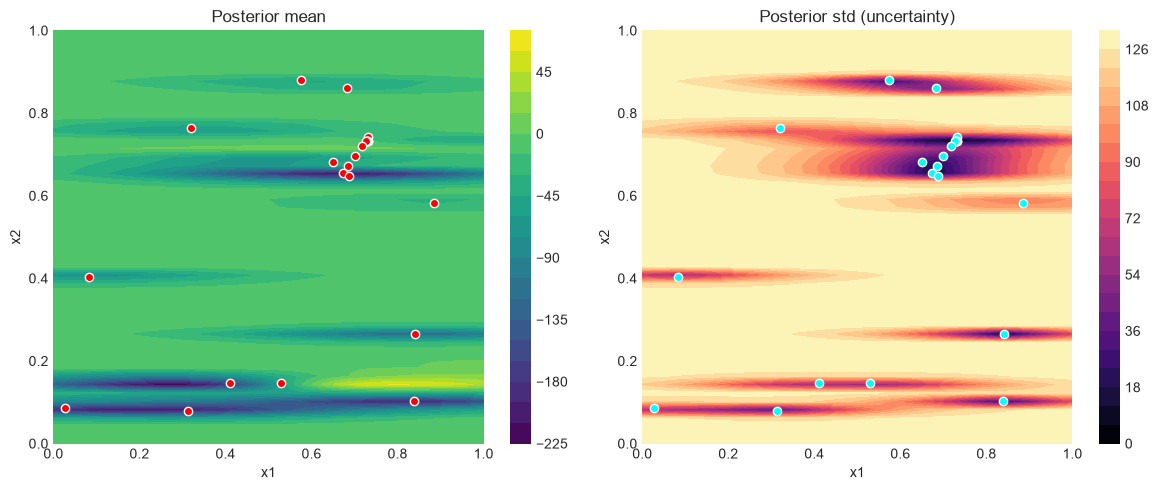

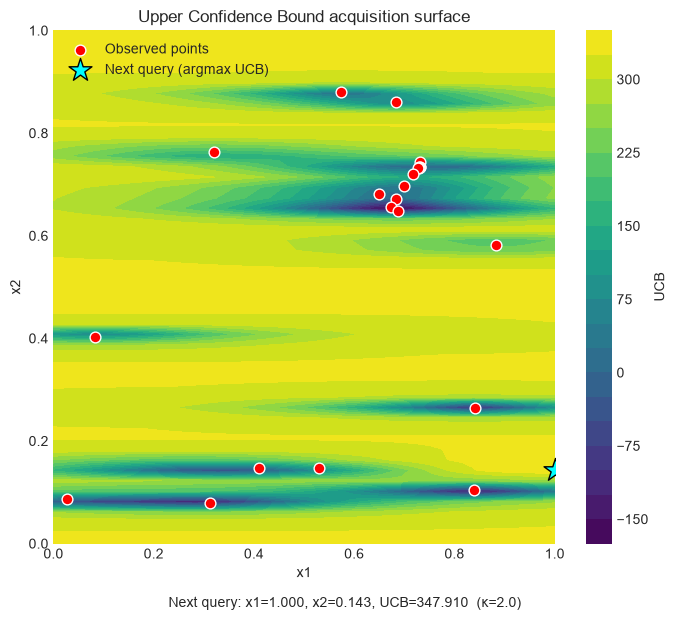

UCB Grid Search best_x1=np.float64(1.0)  best_x2=np.float64(0.14285714285714285)  347.9103835397434 
UCB Optimiser next_x=array([0., 1.])  next_y=325.83857888712186 
mu_contribution=array([-2.36949558e-06]) sigma_contribution=array([325.83858126]) est_next_y=array([325.83857889]) sigma_pct=100.00000072719921

Function 2: Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima.  (no=10) (n=23)
Imagine a black box, or a mystery ML model, that takes two numbers as input and returns a log-likelihood score. Your goal is to maximise that score, but each output is noisy, and depending on where you start, you might get stuck in a local optimum.

To tackle this, you use Bayesian optimisation, which selects the next inputs based on what it has learned so far. It balances exploration with exploitation, making it well suited to noisy outputs and complex functions with many local peaks.
[2.         0.61120522 0.64450101]
X_samples=array([[0.14269907, 0.3490051

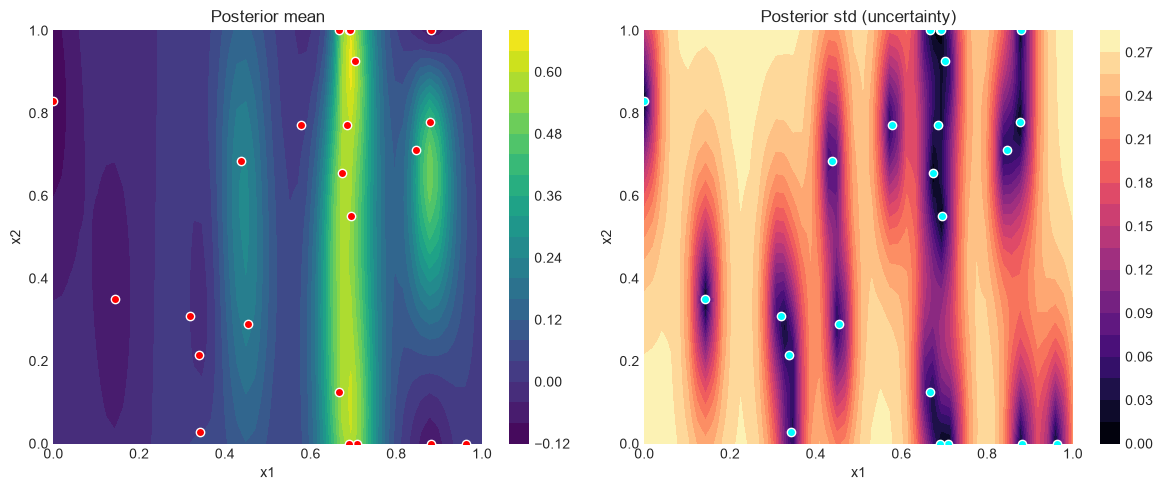

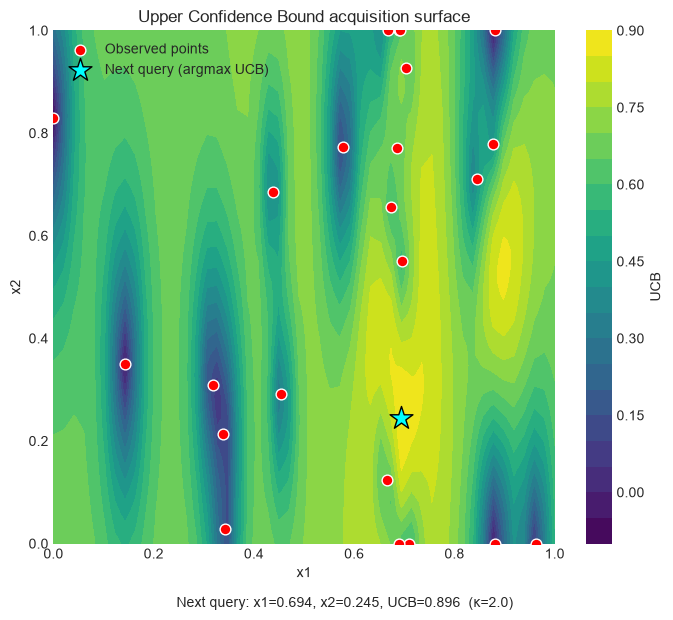

UCB Grid Search best_x1=np.float64(0.6938775510204082)  best_x2=np.float64(0.24489795918367346)  0.8957887254024607 
UCB Optimiser next_x=array([0.69554866, 0.2383944 ])  next_y=0.8963113356815935 
mu_contribution=array([0.58262683]) sigma_contribution=array([0.31368451]) est_next_y=array([0.89631134]) sigma_pct=34.997271149624886

Function 3: Minimise drug side effects (framed as maximisation) across 3 compound-dose inputs.  (n=28)
You're working on a drug discovery project, testing combinations of three compounds to create a new medicine.

Each experiment is stored in initial_inputs.npy as a 3D array, where each row lists the amounts of the three compounds used. After each experiment, you record the number of adverse reactions, stored in initial_outputs.npy as a 1D array.

Your goal is to minimise side effects; in this competition, it is framed as maximisation by optimising a transformed output (e.g. the negative of side effects).
[ 3.         -0.03483531 -0.03483285]
Fitted kernel: 

In [265]:
for challenge_function_idx in range(1, 3):
    predict_with_graph(challenge_function_idx)

for challenge_function_idx in range(3, 9):
    predict_without_graph(challenge_function_idx)    

### 12. Output results in form suitable for upload to Portal

In [266]:
for challenge_function_idx in range(1, 9):
    # number of reading elements each time a reading is taken
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    portal_output = ""
    for reading_dim_idx in range (0, reading_dim_cnt):
        if reading_dim_idx == reading_dim_cnt - 1:     
            portal_output = portal_output + f"{next_submission[challenge_function_idx][reading_dim_idx]:.6f}" 
        else:
            portal_output = portal_output + f"{next_submission[challenge_function_idx][reading_dim_idx]:.6f}" + "-"   
    print (challenge_function_idx, portal_output, 
                '*  prediction',submission_results[challenge_function_idx]["prediction"],
                ' ',submission_results[challenge_function_idx]["sigma_percentage"],'%'
                                      )
for challenge_function_idx in range(1, 9):
    print(f"{challenge_function_idx} {submission_results[challenge_function_idx]['sigma_percentage']:.0f}%")

print("\nLength Scales ")
for challenge_function_idx in range(1, 9):
    print(f"{challenge_function_idx} {length_scales[challenge_function_idx]}")


1 0.688000-0.648000 *  prediction 325.83857888712186   100.00000072719921 %
2 0.695000-0.550000 *  prediction 0.8963113356815935   34.997271149624886 %
3 0.913314-0.614527-0.499783 *  prediction 0.02220220785097697   214.13482613410642 %
4 0.000000-1.000000-1.000000-0.000000 *  prediction 21.19012686047452   192.2643270476854 %
5 1.000000-0.880097-1.000000-1.000000 *  prediction 7625.215938977926   0.8495161794500439 %
6 0.000000-0.000000-1.000000-1.000000-1.000000 *  prediction 0.6698210260737807   307.9134561974585 %
7 0.278741-0.179793-0.711817-0.576048-0.608893-0.000000 *  prediction 2.6078346464676168   21.335290713718173 %
8 0.135544-0.055316-0.204245-0.268660-1.000000-0.372878-0.156072-0.178767 *  prediction 10.017309635221716   0.6784270421812938 %
1 100%
2 35%
3 214%
4 192%
5 1%
6 308%
7 21%
8 1%

Length Scales 
1 [0.32072939 0.01251585 0.         0.         0.         0.
 0.         0.        ]
2 [0.04741567 0.37202601 0.         0.         0.         0.
 0.         0.       